# White Blood Cell Classification — Pipeline finale (K-Fold Multi-GPU)

**IMA205 — Machine Learning Challenge**

**Pipeline (V14)** : ConvNeXt-Tiny → embeddings 768-d → XGBoost — validé par **5-fold stratifié** — parallélisé sur **2 GPU**.

Branche retenue après V0–V13. Les anciennes expérimentations sont archivées dans `archive nb/`, `resultats_archive.md` et `journal_de_bord.md`.

## 1. Imports et configuration

In [20]:
# === Imports ===
import os
import sys
import time
import copy
import warnings
import gc
import pickle
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import torchvision
from torchvision import transforms, models

from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost", "-q"])
    import xgboost as xgb

warnings.filterwarnings("ignore")
%matplotlib inline

In [21]:
# === Configuration ===

# Paths
DATA_DIR = os.path.dirname(os.path.abspath("__file__"))
if not os.path.exists(os.path.join(DATA_DIR, "train_metadata.csv")):
    DATA_DIR = os.path.expanduser("~/kaggle-im05")

TRAIN_DIR  = os.path.join(DATA_DIR, "train")
TEST_DIR   = os.path.join(DATA_DIR, "test")
TRAIN_CSV  = os.path.join(DATA_DIR, "train_metadata.csv")
TEST_CSV   = os.path.join(DATA_DIR, "test_metadata.csv")
OUTPUT_DIR = os.path.join(DATA_DIR, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Column names
COL_ID    = "ID"
COL_LABEL = "label"

# Seed
SEED = 42

# --- Backbone parameters ---
IMG_SIZE     = 224
BATCH_SIZE   = 32           # ConvNeXt-Tiny needs smaller batches
NUM_EPOCHS   = 30
LR           = 1e-4
WEIGHT_DECAY = 5e-4         # optimisé en V7
PATIENCE     = 4            # early stopping sur val macro-F1
NUM_WORKERS  = 2
DROPOUT      = 0.3

# --- K-Fold ---
K_FOLDS = 5                 # 5-fold stratifié

# --- Multi-GPU ---
NUM_GPUS = 1                # nombre de GPU pour la parallélisation

# --- XGBoost parameters ---
XGB_PARAMS = dict(
    objective="multi:softprob",
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=SEED,
    use_label_encoder=False,
    eval_metric="mlogloss",
    early_stopping_rounds=30,
    verbosity=0,
)

# Device & seeds (pour les cellules interactives du notebook)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.enabled = False

print(f"Device      : {device}")
print(f"GPU dispo   : {torch.cuda.device_count()}")
print(f"Backbone    : ConvNeXt-Tiny (pretrained ImageNet)")
print(f"Classifieur : XGBoost (CPU)")
print(f"K-Fold      : {K_FOLDS}-fold stratifié")
print(f"Parallèle   : {NUM_GPUS} GPU (1 fold = 1 process = 1 GPU)")
print(f"Image size  : {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size  : {BATCH_SIZE}")

Device      : cuda
GPU dispo   : 1
Backbone    : ConvNeXt-Tiny (pretrained ImageNet)
Classifieur : XGBoost (CPU)
K-Fold      : 5-fold stratifié
Parallèle   : 1 GPU (1 fold = 1 process = 1 GPU)
Image size  : 224x224
Batch size  : 32


## 2. Chargement des données

In [22]:
# Lecture des métadonnées
df_train_full = pd.read_csv(TRAIN_CSV)
df_test       = pd.read_csv(TEST_CSV)

# Chemins des images
df_train_full["path"] = df_train_full[COL_ID].apply(lambda x: os.path.join(TRAIN_DIR, x))
df_test["path"]       = df_test[COL_ID].apply(lambda x: os.path.join(TEST_DIR, x))

# Filtrer les fichiers vides (images corrompues)
df_train_full["filesize"] = df_train_full["path"].apply(
    lambda p: os.path.getsize(p) if os.path.exists(p) else 0
)
n_before = len(df_train_full)
df_train_full = df_train_full[df_train_full["filesize"] > 0].reset_index(drop=True)
print(f"Images train valides : {len(df_train_full)} / {n_before}")

# Classes
classes = sorted(df_train_full[COL_LABEL].unique())
num_classes = len(classes)
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}

print(f"Nombre de classes : {num_classes}")
print(f"Classes : {classes}")
print()
print(df_train_full[COL_LABEL].value_counts().sort_index())

Images train valides : 28901 / 28901
Nombre de classes : 13
Classes : ['BA', 'BL', 'BNE', 'EO', 'LY', 'MMY', 'MO', 'MY', 'PC', 'PLY', 'PMY', 'SNE', 'VLY']

label
BA       415
BL      2012
BNE      391
EO       861
LY      8101
MMY      360
MO      2746
MY       441
PC        68
PLY       11
PMY      114
SNE    13015
VLY      366
Name: count, dtype: int64


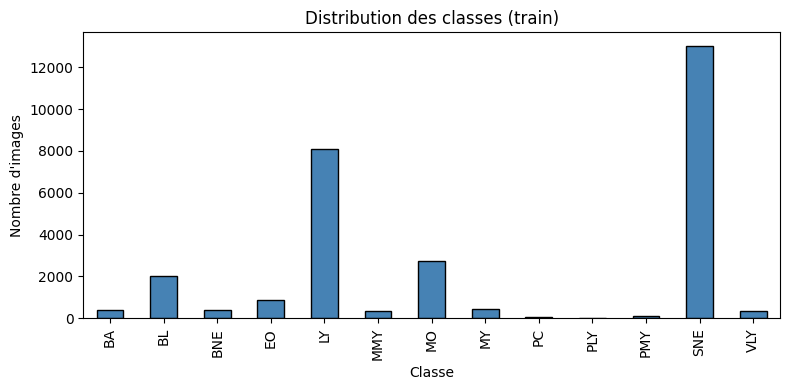

In [23]:
# Distribution des classes
fig, ax = plt.subplots(figsize=(8, 4))
df_train_full[COL_LABEL].value_counts().sort_index().plot.bar(
    ax=ax, color="steelblue", edgecolor="k"
)
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre d'images")
ax.set_title("Distribution des classes (train)")
plt.tight_layout()
plt.show()

## 3. Transforms et Dataset

Les splits train/val sont gérés par le protocole k-fold (section 5).  
Ici on définit les transforms et la classe Dataset.

In [24]:
# Normalisation ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Augmentations train (baseline V7)
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Validation / Test / Extraction d'embeddings : pas d'augmentation
val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

In [25]:
class WBCDataset(Dataset):
    def __init__(self, dataframe, transform=None, has_labels=True):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["path"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        if self.has_labels:
            label = class_to_idx[row[COL_LABEL]]
            return img, label
        else:
            return img, -1

## 4. Backbone — ConvNeXt-Tiny

ConvNeXt-Tiny (Liu et al., 2022) : architecture convolutive moderne inspirée des Transformers.
- 27.8M paramètres, embeddings 768-d
- Pré-entraîné sur ImageNet
- Sélectionné en V11 comme meilleur backbone (domine SE-ResNet-18 dans toutes les configurations)

In [26]:
class ConvNeXtTinyBackbone(nn.Module):
    """ConvNeXt-Tiny pretrained ImageNet — extracteur d'embeddings 768-d."""
    def __init__(self, num_classes, dropout_p=0.3):
        super().__init__()
        backbone = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        self.features = backbone.features
        self.avgpool = backbone.avgpool
        self.embed_dim = 768
        self.norm = nn.LayerNorm(self.embed_dim)
        self.fc = nn.Sequential(
            nn.Dropout(p=dropout_p),
            nn.Linear(self.embed_dim, num_classes)
        )

    def get_embeddings(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.norm(x)
        return x

    def forward(self, x):
        return self.fc(self.get_embeddings(x))


def create_backbone(dropout_p=DROPOUT):
    """Crée un ConvNeXt-Tiny pré-entraîné."""
    return ConvNeXtTinyBackbone(num_classes, dropout_p=dropout_p).to(device)


@torch.no_grad()
def extract_embeddings(model, loader):
    """Extrait les embeddings 768-d pour tous les exemples d'un loader."""
    model.eval()
    all_emb, all_labels = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        emb = model.get_embeddings(imgs)
        all_emb.append(emb.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return np.vstack(all_emb), np.array(all_labels)


# Vérification
_test = create_backbone()
n_params = sum(p.numel() for p in _test.parameters())
print(f"ConvNeXt-Tiny : {n_params:,} paramètres | embed_dim={_test.embed_dim}")
del _test; torch.cuda.empty_cache()

ConvNeXt-Tiny : 27,830,125 paramètres | embed_dim=768


## 5. Fonctions d'entraînement et d'évaluation

Fonctions réutilisées dans chaque fold du k-fold.

In [27]:
def train_one_epoch(model, loader, criterion, optimizer):
    """Entraîne le modèle sur une epoch."""
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []
    n_batches = len(loader)

    for batch_idx, (imgs, labels) in enumerate(loader):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        if (batch_idx + 1) % max(1, n_batches // 4) == 0:
            pct = 100 * (batch_idx + 1) / n_batches
            print(f"    [train] {batch_idx+1}/{n_batches} ({pct:.0f}%)", end="\r")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds, average="macro")
    return epoch_loss, epoch_f1


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Évalue le modèle sur le set de validation."""
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []

    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        running_loss += loss.item() * imgs.size(0)
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds, average="macro")
    return epoch_loss, epoch_f1, np.array(all_preds), np.array(all_labels)

## 6. K-Fold parallèle sur 2 GPU

Stratégie : **1 fold = 1 process = 1 GPU**.  
Chaque fold est lancé via `subprocess` avec `CUDA_VISIBLE_DEVICES` pour l'assigner à un GPU.  
Avec 2 GPU, **2 folds tournent en parallèle**. Quand un fold finit, le suivant se lance sur le GPU libéré.

```
GPU 0 :  fold 0 ──────→ fold 2 ──────→ fold 4 ──────→
GPU 1 :  fold 1 ──────→ fold 3 ──────→
```

Le script `fold_worker.py` exécute un fold complet : backbone → embeddings → XGBoost → test probas.  
Les résultats sont sauvegardés dans `outputs/fold_X/results.pkl`.

In [28]:
# --- Préparation de la config et des splits ---
labels_all = df_train_full[COL_LABEL].values
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)

splits = []
for train_idx, val_idx in skf.split(df_train_full, labels_all):
    splits.append({"train_idx": train_idx, "val_idx": val_idx})

config = {
    "df_train": df_train_full,
    "df_test": df_test,
    "splits": splits,
    "class_to_idx": class_to_idx,
    "num_classes": num_classes,
    "col_label": COL_LABEL,
    "seed": SEED,
    "k_folds": K_FOLDS,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "num_epochs": NUM_EPOCHS,
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "patience": PATIENCE,
    "num_workers": NUM_WORKERS,
    "dropout": DROPOUT,
    "xgb_params": XGB_PARAMS,
    "output_dir": OUTPUT_DIR,
}

config_path = os.path.join(OUTPUT_DIR, "kfold_config.pkl")
with open(config_path, "wb") as f:
    pickle.dump(config, f)

print(f"Config sauvegardée : {config_path}")
print(f"  {K_FOLDS} folds, {NUM_GPUS} GPU")
for i, s in enumerate(splits):
    print(f"  Fold {i+1}: train={len(s['train_idx'])} val={len(s['val_idx'])}")

Config sauvegardée : /home/infres/sryszfeld-24/kaggle-im05/outputs/kfold_config.pkl
  5 folds, 1 GPU
  Fold 1: train=23120 val=5781
  Fold 2: train=23121 val=5780
  Fold 3: train=23121 val=5780
  Fold 4: train=23121 val=5780
  Fold 5: train=23121 val=5780


In [29]:
# --- Lancement parallèle des folds sur 2 GPU ---
worker_script = os.path.join(DATA_DIR, "fold_worker.py")
python_exe = sys.executable

print(f"Lancement du {K_FOLDS}-fold stratifié sur {NUM_GPUS} GPU")
print(f"  Worker : {worker_script}")
print(f"  Python : {python_exe}")
print()

t_total = time.time()
pending = list(range(K_FOLDS))
running = {}    # gpu_id → (fold_idx, process, log_file, t_start)
completed = []

while pending or running:
    # Lancer des folds sur les GPU libres
    free_gpus = [g for g in range(NUM_GPUS) if g not in running]
    while pending and free_gpus:
        fold_idx = pending.pop(0)
        gpu_id = free_gpus.pop(0)

        fold_dir = os.path.join(OUTPUT_DIR, f"fold_{fold_idx}")
        os.makedirs(fold_dir, exist_ok=True)
        log_path = os.path.join(fold_dir, "log.txt")
        log_file = open(log_path, "w")

        # Passer CUDA_VISIBLE_DEVICES via l'environnement du subprocess
        env = os.environ.copy()
        env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)

        cmd = [python_exe, worker_script,
               "--fold", str(fold_idx),
               "--gpu", str(gpu_id),
               "--config", config_path]

        proc = subprocess.Popen(cmd, stdout=log_file, stderr=subprocess.STDOUT, env=env)
        running[gpu_id] = (fold_idx, proc, log_file, time.time())
        print(f"  ▶ Fold {fold_idx+1} → GPU {gpu_id} (PID {proc.pid})")

    # Attendre qu'un fold finisse (poll toutes les 10s)
    if running:
        time.sleep(10)
        for gpu_id in list(running.keys()):
            fold_idx, proc, log_file, t_start = running[gpu_id]
            if proc.poll() is not None:
                log_file.close()
                elapsed_fold = (time.time() - t_start) / 60
                if proc.returncode == 0:
                    print(f"  ✓ Fold {fold_idx+1} terminé (GPU {gpu_id}) — {elapsed_fold:.1f} min")
                else:
                    print(f"  ✗ Fold {fold_idx+1} ERREUR code={proc.returncode} (GPU {gpu_id})")
                    log_p = os.path.join(OUTPUT_DIR, f"fold_{fold_idx}", "log.txt")
                    print(f"    → Voir log : {log_p}")
                completed.append(fold_idx)
                del running[gpu_id]

elapsed_total = time.time() - t_total
print(f"\n{'='*60}")
print(f" K-FOLD TERMINÉ — {elapsed_total/60:.1f} min total ({NUM_GPUS} GPU)")
print(f"{'='*60}")

Lancement du 5-fold stratifié sur 1 GPU
  Worker : /home/infres/sryszfeld-24/kaggle-im05/fold_worker.py
  Python : /home/infres/sryszfeld-24/venvs/monenv/bin/python

  ▶ Fold 1 → GPU 0 (PID 1839440)


  ✓ Fold 1 terminé (GPU 0) — 74.3 min
  ▶ Fold 2 → GPU 0 (PID 1857671)
  ✓ Fold 2 terminé (GPU 0) — 50.8 min
  ▶ Fold 3 → GPU 0 (PID 1869937)
  ✓ Fold 3 terminé (GPU 0) — 31.3 min
  ▶ Fold 4 → GPU 0 (PID 1877904)
  ✓ Fold 4 terminé (GPU 0) — 35.2 min
  ▶ Fold 5 → GPU 0 (PID 1887345)
  ✓ Fold 5 terminé (GPU 0) — 39.3 min

 K-FOLD TERMINÉ — 231.0 min total (1 GPU)


In [30]:
# --- Chargement des résultats depuis le disque ---
fold_results = []
for fold_idx in range(K_FOLDS):
    results_path = os.path.join(OUTPUT_DIR, f"fold_{fold_idx}", "results.pkl")
    with open(results_path, "rb") as f:
        fold_results.append(pickle.load(f))

print(f"{len(fold_results)} folds chargés :")
for r in fold_results:
    print(f"  Fold {r['fold']} (GPU {r['gpu']}) — "
          f"backbone F1={r['backbone_val_f1']:.4f}, "
          f"XGB F1={r['xgb_val_f1']:.4f}, "
          f"temps={r['elapsed_min']:.1f} min")

5 folds chargés :
  Fold 1 (GPU 0) — backbone F1=0.7052, XGB F1=0.6918, temps=74.2 min
  Fold 2 (GPU 0) — backbone F1=0.7284, XGB F1=0.6619, temps=50.6 min
  Fold 3 (GPU 0) — backbone F1=0.7225, XGB F1=0.6685, temps=31.2 min
  Fold 4 (GPU 0) — backbone F1=0.7289, XGB F1=0.7566, temps=35.0 min
  Fold 5 (GPU 0) — backbone F1=0.7435, XGB F1=0.6886, temps=39.1 min


## 7. Résultats du K-Fold

In [31]:
# --- Tableau récapitulatif par fold ---
results_df = pd.DataFrame([{
    "Fold": r["fold"],
    "GPU": r["gpu"],
    "Backbone val F1": r["backbone_val_f1"],
    "XGB val F1": r["xgb_val_f1"],
    "XGB trees": r["xgb_best_iter"],
    "Temps (min)": round(r["elapsed_min"], 1),
} for r in fold_results])

print("Résultats par fold :")
print(results_df.to_string(index=False))
print()

# Statistiques agrégées
f1_scores = results_df["XGB val F1"]
print(f"Macro-F1 (XGBoost) — mean={f1_scores.mean():.4f} ± {f1_scores.std():.4f}  "
      f"min={f1_scores.min():.4f}  max={f1_scores.max():.4f}")

backbone_f1 = results_df["Backbone val F1"]
print(f"Macro-F1 (Backbone) — mean={backbone_f1.mean():.4f} ± {backbone_f1.std():.4f}  "
      f"min={backbone_f1.min():.4f}  max={backbone_f1.max():.4f}")

print(f"\nTemps total folds    : {results_df['Temps (min)'].sum():.1f} min (séquentiel)")
print(f"Temps réel (parallèle): {elapsed_total/60:.1f} min ({NUM_GPUS} GPU)")

Résultats par fold :
 Fold  GPU  Backbone val F1  XGB val F1  XGB trees  Temps (min)
    1    0         0.705175    0.691808         44         74.2
    2    0         0.728398    0.661894         43         50.6
    3    0         0.722454    0.668535         50         31.2
    4    0         0.728883    0.756584         49         35.0
    5    0         0.743528    0.688617         49         39.1

Macro-F1 (XGBoost) — mean=0.6935 ± 0.0375  min=0.6619  max=0.7566
Macro-F1 (Backbone) — mean=0.7257 ± 0.0138  min=0.7052  max=0.7435

Temps total folds    : 230.1 min (séquentiel)
Temps réel (parallèle): 231.0 min (1 GPU)


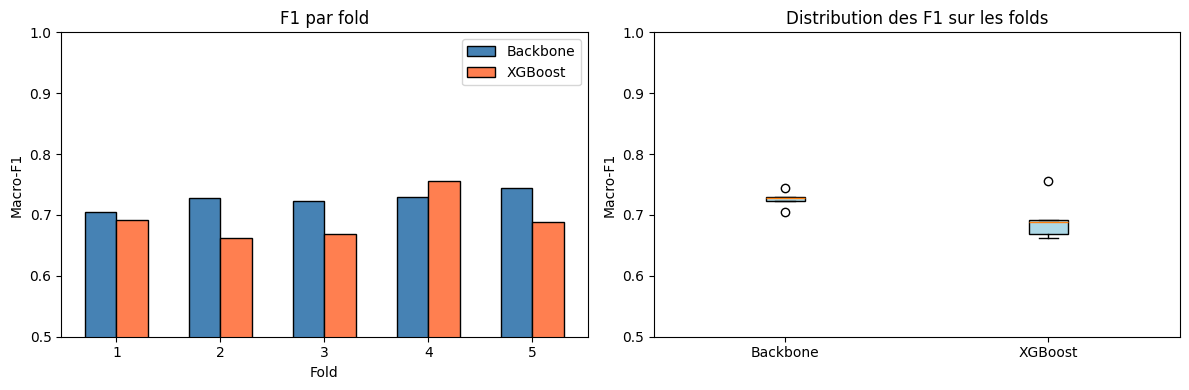

In [32]:
# --- Barplot des F1 par fold ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# F1 par fold
ax = axes[0]
x = results_df["Fold"]
ax.bar(x - 0.15, results_df["Backbone val F1"], width=0.3, label="Backbone", color="steelblue", edgecolor="k")
ax.bar(x + 0.15, results_df["XGB val F1"],      width=0.3, label="XGBoost",  color="coral",     edgecolor="k")
ax.set_xlabel("Fold")
ax.set_ylabel("Macro-F1")
ax.set_title("F1 par fold")
ax.set_xticks(x)
ax.legend()
ax.set_ylim(0.5, 1.0)

# Distribution globale
ax = axes[1]
ax.boxplot([results_df["Backbone val F1"], results_df["XGB val F1"]],
           labels=["Backbone", "XGBoost"],
           patch_artist=True,
           boxprops=dict(facecolor="lightblue"))
ax.set_ylabel("Macro-F1")
ax.set_title("Distribution des F1 sur les folds")
ax.set_ylim(0.5, 1.0)

plt.tight_layout()
plt.show()

Meilleur fold : 4  (XGB val F1 = 0.7566)

              precision    recall  f1-score   support

          BA       0.95      0.95      0.95        83
          BL       0.90      0.89      0.89       403
         BNE       0.42      0.22      0.29        78
          EO       0.95      0.92      0.94       172
          LY       0.94      0.97      0.96      1620
         MMY       0.56      0.49      0.52        72
          MO       0.89      0.90      0.90       549
          MY       0.68      0.64      0.66        88
          PC       1.00      0.50      0.67        14
         PLY       1.00      1.00      1.00         2
         PMY       0.47      0.39      0.43        23
         SNE       0.97      0.98      0.97      2603
         VLY       0.73      0.60      0.66        73

    accuracy                           0.93      5780
   macro avg       0.81      0.73      0.76      5780
weighted avg       0.93      0.93      0.93      5780



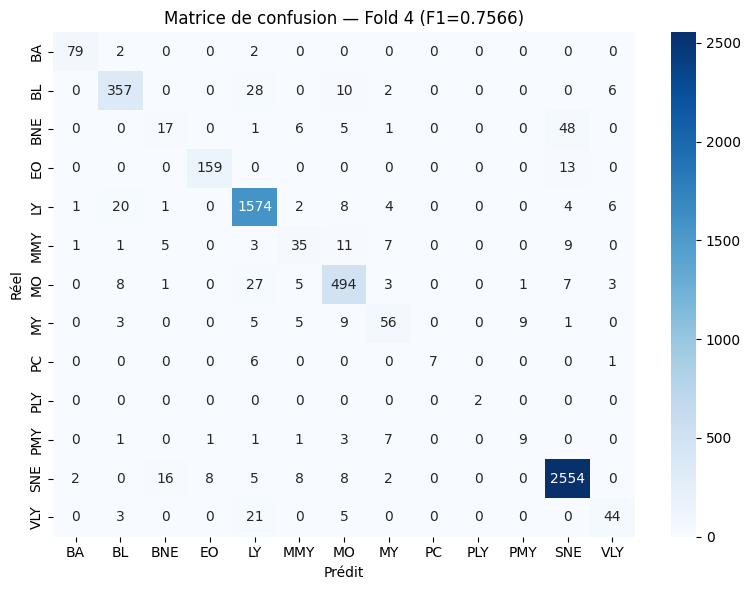

In [33]:
# --- Évaluation détaillée du meilleur fold ---
best_fold_idx = int(f1_scores.idxmax())
best = fold_results[best_fold_idx]
print(f"Meilleur fold : {best['fold']}  (XGB val F1 = {best['xgb_val_f1']:.4f})")
print()

# Classification report
target_names = [idx_to_class[i] for i in range(num_classes)]
print(classification_report(best["val_labels"], best["val_preds"], target_names=target_names))

# Confusion matrix
cm = confusion_matrix(best["val_labels"], best["val_preds"])
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names, ax=ax)
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")
ax.set_title(f"Matrice de confusion — Fold {best['fold']} (F1={best['xgb_val_f1']:.4f})")
plt.tight_layout()
plt.show()

## 8. Prédiction test — Ensemble des folds

Stratégie : **moyenne des probabilités** XGBoost sur les 5 folds, puis `argmax`.

In [34]:
# --- Moyenne des probabilités sur les folds ---
all_test_proba = np.stack([r["test_proba"] for r in fold_results])  # (K, n_test, n_classes)
mean_proba = all_test_proba.mean(axis=0)                           # (n_test, n_classes)
test_preds = mean_proba.argmax(axis=1)
test_labels_pred = [idx_to_class[i] for i in test_preds]

print(f"Ensemble de {K_FOLDS} folds — {len(test_labels_pred)} prédictions test")
print()
print("Distribution des prédictions :")
print(pd.Series(test_labels_pred).value_counts().sort_index())

Ensemble de 5 folds — 9634 prédictions test

Distribution des prédictions :
BA      133
BL      676
BNE      59
EO      273
LY     2788
MMY     101
MO      922
MY      142
PC        9
PMY      33
SNE    4426
VLY      72
Name: count, dtype: int64


In [35]:
# --- Création du fichier de soumission ---
submission = pd.DataFrame({
    COL_ID:    df_test[COL_ID].values,
    COL_LABEL: test_labels_pred
})

sub_path = os.path.join(OUTPUT_DIR, "submission_cnn.csv")
submission.to_csv(sub_path, index=False)
print(f"Soumission sauvegardée : {sub_path}")
print(f"Nombre de lignes : {len(submission)}")
print()
submission.head(10)

Soumission sauvegardée : /home/infres/sryszfeld-24/kaggle-im05/outputs/submission_cnn.csv
Nombre de lignes : 9634



,ID,label
0,test_00000.png,LY
1,test_00001.png,BL
2,test_00002.png,SNE
3,test_00003.png,SNE
4,test_00004.png,LY
5,test_00005.png,MO
6,test_00006.png,SNE
7,test_00007.png,LY
8,test_00008.png,EO
9,test_00009.png,BA


## 9. Récapitulatif

| Paramètre | Valeur |
|---|---|
| **Backbone** | ConvNeXt-Tiny (pretrained ImageNet, 27.8M params) |
| **Embeddings** | 768-d |
| **Classifieur** | XGBoost (max_depth=6, lr=0.1, subsample=0.8) — CPU |
| **Validation** | 5-fold stratifié (StratifiedKFold) |
| **Parallélisation** | 2 GPU (1 fold = 1 process = 1 GPU, file d'attente) |
| **Prédiction test** | Moyenne des probabilités XGBoost sur les 5 folds |
| **Entraînement backbone** | AdamW (lr=1e-4, wd=5e-4), early stopping (patience=4) |
| **Sampler** | WeightedRandomSampler (par fold) |
| **Loss backbone** | CrossEntropyLoss standard |
| **Augmentations** | HFlip, VFlip, Rotation(15°), ColorJitter(0.1) |
| **Image size** | 224×224 |
| **Sorties par fold** | `outputs/fold_X/results.pkl`, `outputs/fold_X/backbone_best.pth`, `outputs/fold_X/log.txt` |

**Historique complet** : voir `journal_de_bord.md` et `resultats_archive.md`.  
**Notebooks archivés** : voir `archive nb/`.